<a href="https://colab.research.google.com/github/necsilva28/prediction-of-cirrhosis-stage-com-ML/blob/main/prediction_of_cirrhosis_stage_com_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [152]:
import pandas as pd

In [153]:
dados = pd.read_csv('/content/cirrhosis.csv')


In [154]:
dados = dados.drop('ID', axis=1)
dados

,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,681,D,NaN,24472,F,NaN,NaN,NaN,N,1.2,NaN,2.96,NaN,NaN,NaN,NaN,174.0,10.9,3.0
414,1103,C,NaN,14245,F,NaN,NaN,NaN,N,0.9,NaN,3.83,NaN,NaN,NaN,NaN,180.0,11.2,4.0
415,1055,C,NaN,20819,F,NaN,NaN,NaN,N,1.6,NaN,3.42,NaN,NaN,NaN,NaN,143.0,9.9,3.0
416,691,C,NaN,21185,F,NaN,NaN,NaN,N,0.8,NaN,3.75,NaN,NaN,NaN,NaN,269.0,10.4,3.0


In [155]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         418 non-null    int64  
 1   Status         418 non-null    object 
 2   Drug           312 non-null    object 
 3   Age            418 non-null    int64  
 4   Sex            418 non-null    object 
 5   Ascites        312 non-null    object 
 6   Hepatomegaly   312 non-null    object 
 7   Spiders        312 non-null    object 
 8   Edema          418 non-null    object 
 9   Bilirubin      418 non-null    float64
 10  Cholesterol    284 non-null    float64
 11  Albumin        418 non-null    float64
 12  Copper         310 non-null    float64
 13  Alk_Phos       312 non-null    float64
 14  SGOT           312 non-null    float64
 15  Tryglicerides  282 non-null    float64
 16  Platelets      407 non-null    float64
 17  Prothrombin    416 non-null    float64
 18  Stage     

In [156]:
colunas_cat = ['Drug', 'Ascites', 'Hepatomegaly', 'Spiders']
dados[colunas_cat] = dados[colunas_cat].fillna('nenhum')


In [157]:
dados = dados.fillna(0)

In [158]:
dados = dados.dropna(subset=["Stage"])

In [159]:
dados

,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,681,D,nenhum,24472,F,nenhum,nenhum,nenhum,N,1.2,0.0,2.96,0.0,0.0,0.00,0.0,174.0,10.9,3.0
414,1103,C,nenhum,14245,F,nenhum,nenhum,nenhum,N,0.9,0.0,3.83,0.0,0.0,0.00,0.0,180.0,11.2,4.0
415,1055,C,nenhum,20819,F,nenhum,nenhum,nenhum,N,1.6,0.0,3.42,0.0,0.0,0.00,0.0,143.0,9.9,3.0
416,691,C,nenhum,21185,F,nenhum,nenhum,nenhum,N,0.8,0.0,3.75,0.0,0.0,0.00,0.0,269.0,10.4,3.0


In [160]:
from sklearn.preprocessing import OneHotEncoder

In [161]:
colunas_categoricas = ['Status', 'Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']

In [162]:
encoder = OneHotEncoder(drop='if_binary')

dados_categorico = dados[colunas_categoricas]
dados_encoded = pd.DataFrame(encoder.fit_transform(dados_categorico).toarray(),
                             columns=encoder.get_feature_names_out(colunas_categoricas))
dados_final = pd.concat([dados.drop(colunas_categoricas, axis=1), dados_encoded],axis=1)

In [163]:
dados_final

,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,...,Ascites_nenhum,Hepatomegaly_N,Hepatomegaly_Y,Hepatomegaly_nenhum,Spiders_N,Spiders_Y,Spiders_nenhum,Edema_N,Edema_S,Edema_Y
0,400,21464,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,4500,20617,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,1012,25594,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,1925,19994,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,1504,13918,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,681,24472,1.2,0.0,2.96,0.0,0.0,0.00,0.0,174.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
414,1103,14245,0.9,0.0,3.83,0.0,0.0,0.00,0.0,180.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
415,1055,20819,1.6,0.0,3.42,0.0,0.0,0.00,0.0,143.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
416,691,21185,0.8,0.0,3.75,0.0,0.0,0.00,0.0,269.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0


In [164]:
dados_final = dados_final.fillna(0)

In [195]:
dados_final = dados_final[dados_final['Stage'] != 0]

In [196]:
dados_final

,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,...,Ascites_nenhum,Hepatomegaly_N,Hepatomegaly_Y,Hepatomegaly_nenhum,Spiders_N,Spiders_Y,Spiders_nenhum,Edema_N,Edema_S,Edema_Y
0,400,21464,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,4500,20617,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,1012,25594,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,1925,19994,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,1504,13918,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,681,24472,1.2,0.0,2.96,0.0,0.0,0.00,0.0,174.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
414,1103,14245,0.9,0.0,3.83,0.0,0.0,0.00,0.0,180.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
415,1055,20819,1.6,0.0,3.42,0.0,0.0,0.00,0.0,143.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
416,691,21185,0.8,0.0,3.75,0.0,0.0,0.00,0.0,269.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0


In [197]:
X = dados_final.drop('Stage', axis=1)
Y = dados_final['Stage']

In [198]:
from sklearn.model_selection import train_test_split

In [199]:
X, X_teste, Y, Y_teste = train_test_split(X,Y, test_size=0.15, stratify=Y, random_state=0)
X_treino, X_val, Y_treino, Y_val = train_test_split(X,Y, stratify=Y, random_state=0)

In [200]:
from sklearn.ensemble import RandomForestClassifier

In [201]:
modelo_Random = RandomForestClassifier(random_state=0, max_depth=10)
modelo_Random.fit(X_treino, Y_treino)
Y_pred = modelo_Random.predict(X_val)
print(f'Accuracy de treino: {modelo_Random.score(X_treino, Y_treino)}')
print(f'Accuracy de validacao: {modelo_Random.score(X_val, Y_val)}')

Accuracy de treino: 0.9961832061068703
Accuracy de validacao: 0.5


In [202]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [203]:
matrix_confusao = confusion_matrix(Y_val, Y_pred)

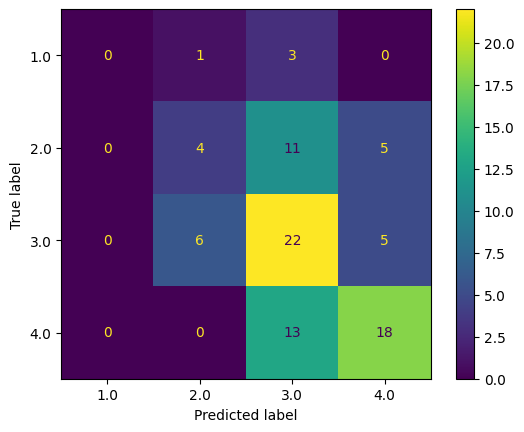

In [204]:
visualizacao = ConfusionMatrixDisplay(confusion_matrix=matrix_confusao, display_labels = modelo_Random.classes_)
visualizacao.plot();

In [205]:
from sklearn.metrics import classification_report

In [206]:
report = classification_report(Y_val, Y_pred)
print('relatorio de classificacao:\n', report)

relatorio de classificacao:
               precision    recall  f1-score   support

         1.0       0.00      0.00      0.00         4
         2.0       0.36      0.20      0.26        20
         3.0       0.45      0.67      0.54        33
         4.0       0.64      0.58      0.61        31

    accuracy                           0.50        88
   macro avg       0.36      0.36      0.35        88
weighted avg       0.48      0.50      0.47        88



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [207]:
from imblearn.over_sampling import SMOTE

In [208]:
oversample = SMOTE(random_state=0,  k_neighbors=3)
X_balanceado, Y_balanceado = oversample.fit_resample(X_treino, Y_treino)

              precision    recall  f1-score   support

         1.0       0.40      0.50      0.44         4
         2.0       0.35      0.40      0.37        20
         3.0       0.49      0.55      0.51        33
         4.0       0.70      0.52      0.59        31

    accuracy                           0.50        88
   macro avg       0.48      0.49      0.48        88
weighted avg       0.52      0.50      0.51        88



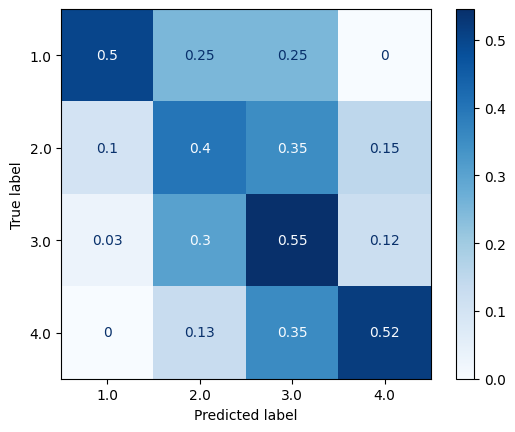

In [209]:
modelo = RandomForestClassifier(random_state=0, max_depth=10)
modelo.fit(X_balanceado, Y_balanceado)
Y_pred = modelo.predict(X_val)
print(classification_report(Y_val, Y_pred))
ConfusionMatrixDisplay.from_predictions(Y_val, Y_pred, normalize='true', cmap='Blues')

In [210]:
from imblearn.pipeline import Pipeline as imbpipeline

In [211]:
modelo = RandomForestClassifier(max_depth=10)
pipeline = imbpipeline([('oversample', SMOTE()), ('floresta', modelo)])

In [212]:
from sklearn.model_selection import cross_validate, StratifiedKFold

In [213]:
print(Y.value_counts())

Stage
3.0    132
4.0    122
2.0     78
1.0     18
Name: count, dtype: int64


In [214]:
skv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_resultados = cross_validate(pipeline, X, Y, cv=skv, scoring='recall_weighted')
cv_resultados['test_score']

array([0.44285714, 0.54285714, 0.48571429, 0.45714286, 0.52857143])

In [215]:
media = cv_resultados['test_score'].mean()
desvio_padrao = cv_resultados['test_score'].std()
print(f'intervalo de confianca: [{media - 2*desvio_padrao}, {min(media + 2*desvio_padrao, 1.0)}]')

intervalo de confianca: [0.4134961045886522, 0.5693610382684906]


              precision    recall  f1-score   support

         1.0       0.67      0.67      0.67         3
         2.0       0.58      0.50      0.54        14
         3.0       0.46      0.57      0.51        23
         4.0       0.68      0.59      0.63        22

    accuracy                           0.56        62
   macro avg       0.60      0.58      0.59        62
weighted avg       0.58      0.56      0.57        62



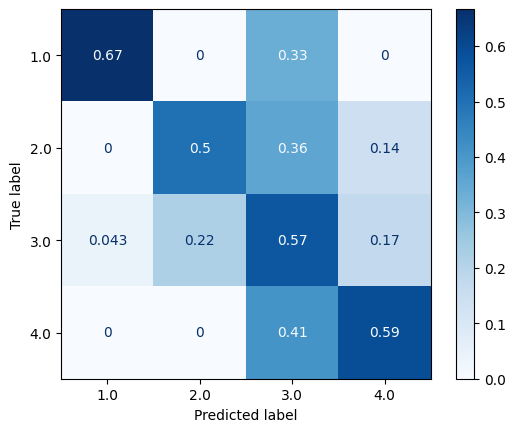

In [216]:
oversample = SMOTE(random_state=0)
X_balanceado, Y_balanceado = oversample.fit_resample(X,Y)
modelo = RandomForestClassifier(random_state=0, max_depth=10)
modelo.fit(X_balanceado, Y_balanceado)
Y_pred = modelo.predict(X_teste)

print(classification_report(Y_teste, Y_pred))
ConfusionMatrixDisplay.from_predictions(Y_teste, Y_pred, normalize='true', cmap='Blues')